# Mechanisms: why does upwind fire reduce conflict?

The reduced form shows that more upwind fire lowers monthly conflict events in conflict-active districts. This notebook tests three explanations against one another using ACLED's actor, event-type and sourcing fields. No new data are downloaded.

1. **Avoidance and mobility.** Haze keeps people indoors and suppresses gatherings. This predicts the largest proportional declines in protests and other crowd-based events, and in urban districts (*kota*).
2. **State capacity diversion.** Police and military are redeployed to firefighting and haze response. This predicts declines in events *initiated by* state forces (state violence against civilians, state interventions in protests), with little change in violence by non-state actors, and larger effects in severe fire years.
3. **Reporting.** Haze or fire coverage crowds out conflict reporting. This predicts the largest declines among events reported by local and subnational sources, among events located or dated imprecisely, and little change in high-salience (fatal) events.

Two further sections test whether conflict is **displaced** rather than averted: to later months (lags of upwind fire) and to neighbouring districts (neighbours' upwind fire).

All specifications are the paper's reduced form, $y_{dt} = \beta_0 Z_{dt} + \beta_1 Z_{d,t-1} + \alpha_d + \gamma_t + \varepsilon_{dt}$, with $Z$ the log upwind FRP, district and year-month fixed effects and standard errors clustered by province. Because outcomes differ widely in their means, each coefficient is also reported as a percentage of the outcome mean, and the Poisson (PPML) coefficient is reported as a proportional effect that is directly comparable across outcomes.

In [1]:
import warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import pyfixest as pf
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')

ROOT         = '/Users/hariaksha/Documents/GitHub/climate-conflict'
PANEL_CSV    = f'{ROOT}/analysis/iv_panel_district.csv'
DISTRICT_SHP = f'{ROOT}/data/administrative/gadm41_IDN_shp/gadm41_IDN_2.shp'
ACLED_XLSX   = f'{ROOT}/data/unrest/ACLED Data_2026-06-10.xlsx'
OUT_CSV      = f'{ROOT}/analysis/output/mechanisms_results.csv'
OUT_PNG      = f'{ROOT}/analysis/output/mechanisms_coefplot.png'
FIG_PNG      = f'{ROOT}/paper/figures/mechanisms_coefplot.png'

INSTR = ['log_upwind_frp', 'log_upwind_frp_l1']
FE    = 'district + year_month'
VCOV  = {'CRV1': 'province'}

panel = pd.read_csv(PANEL_CSV)
print(f'Panel: {len(panel):,} obs, {panel["district"].nunique()} districts')

Panel: 60,125 obs, 481 districts


## 1. Assign ACLED events to districts and build outcome counts

Events are assigned by coordinates exactly as in `identification-checks.ipynb`. The total of all assigned events is checked against the panel's `events` column.

In [2]:
gadm = gpd.read_file(DISTRICT_SHP)[['NAME_1', 'NAME_2', 'TYPE_2', 'geometry']].rename(
    columns={'NAME_1': 'province', 'NAME_2': 'district'})
dup = gadm['district'].duplicated(keep=False)
gadm.loc[dup, 'district'] = gadm.loc[dup, 'district'] + ' (' + gadm.loc[dup, 'province'] + ')'

acled = pd.read_excel(ACLED_XLSX)
acled['event_date'] = pd.to_datetime(acled['event_date'])
acled['year'], acled['month'] = acled['event_date'].dt.year, acled['event_date'].dt.month
ag = gpd.GeoDataFrame(acled, geometry=gpd.points_from_xy(acled['longitude'], acled['latitude']), crs='EPSG:4326')
j = gpd.sjoin(ag, gadm[['district', 'geometry']], how='left', predicate='within')
j = j[~j.index.duplicated(keep='first')]
acled['district'] = j['district'].reindex(acled.index).values
off = acled['district'].isna()
near = gpd.sjoin_nearest(ag.loc[off].to_crs(3395), gadm[['district', 'geometry']].to_crs(3395),
                         how='left', max_distance=20_000)
near = near[~near.index.duplicated(keep='first')]
acled.loc[off, 'district'] = near['district'].reindex(acled.index[off]).values

et, se, i1 = acled['event_type'], acled['sub_event_type'], acled['inter1'].fillna('')
i2 = acled['inter2'].fillna('')
state1 = i1.eq('State forces')
scale = acled['source_scale'].fillna('')
local_src = scale.str.contains('Subnational|Local|Regional|New media|Other', regex=True) & ~scale.eq('National')

O = {
    # event-type decomposition
    'all_events':            et.notna(),
    'peaceful_protest':      se.eq('Peaceful protest'),
    'protest_intervention':  se.isin(['Protest with intervention', 'Excessive force against protesters']),
    'riots':                 et.eq('Riots'),
    'vac':                   et.eq('Violence against civilians'),
    'battles':               et.eq('Battles'),
    'strategic_dev':         et.eq('Strategic developments'),
    # actor decomposition
    'state_initiated':       state1,
    'state_involved':        state1 | i2.eq('State forces') | se.eq('Protest with intervention'),
    'vac_state':             et.eq('Violence against civilians') & state1,
    'vac_nonstate':          et.eq('Violence against civilians') & ~state1,
    'nonstate_violence':     et.isin(['Riots', 'Violence against civilians', 'Battles']) & ~state1,
    # reporting
    'src_national':          scale.eq('National'),
    'src_local':             local_src,
    'imprecise':             (acled['geo_precision'] > 1) | (acled['time_precision'] > 1),
    'precise':               (acled['geo_precision'] == 1) & (acled['time_precision'] == 1),
    'fatal_events':          acled['fatalities'] > 0,
}
for k, v in O.items():
    acled[k] = v.astype(int)
counts = acled.groupby(['district', 'year', 'month'])[list(O)].sum().reset_index()
panel = panel.merge(counts, on=['district', 'year', 'month'], how='left')
panel[list(O)] = panel[list(O)].fillna(0)
print('Check: panel events =', int(panel['events'].sum()), '| reassigned all_events =', int(panel['all_events'].sum()))
print(panel[list(O)].sum().astype(int).to_string())

Check: panel events = 21653 | reassigned all_events = 21653
all_events              21653
peaceful_protest        16683
protest_intervention      822
riots                    1757
vac                      1067
battles                   617
strategic_dev             628
state_initiated          1007
state_involved           3073
vac_state                 630
vac_nonstate              437
nonstate_violence        2738
src_national            19523
src_local                1919
imprecise                1230
precise                 20423
fatal_events              898


## 2. Samples, district types and helpers

The conflict-active sample (conflict in at least 30% of months) is defined exactly as in the paper. *Kota* (cities) are identified from GADM's `TYPE_2`. Severe fire years are the El Niño fire years 2015, 2019 and 2023.

In [3]:
share = panel.groupby('district')['events'].apply(lambda s: (s > 0).mean())
active = share[share >= 0.30].index
dtype = gadm.set_index('district')['TYPE_2']
panel['kota'] = panel['district'].map(dtype).eq('Kota').astype(int)
panel['elnino'] = panel['year'].isin([2015, 2019, 2023]).astype(int)
panel['papua'] = panel['province'].str.contains('Papua').astype(int)
samples = {'full panel': panel, 'active': panel[panel['district'].isin(active)].copy()}
print(f'Active districts: {len(active)}; of which kota: {panel.loc[panel.district.isin(active)].groupby("district").kota.first().sum()}')

def rf(y, d, extra=''):
    rhs = ' + '.join(INSTR) + (f' + {extra}' if extra else '')
    return pf.feols(f'{y} ~ {rhs} | {FE}', data=d, vcov=VCOV)

def ppml(y, d, extra=''):
    rhs = ' + '.join(INSTR) + (f' + {extra}' if extra else '')
    keep = d.groupby('district')[y].transform('sum') > 0
    try:
        return pf.fepois(f'{y} ~ {rhs} | {FE}', data=d[keep], vcov=VCOV)
    except Exception as e:
        return None

def row(group, y, sample, d, m, p=None, term='log_upwind_frp', **kw):
    t = m.tidy()
    mean = d[y].mean()
    r = {'group': group, 'outcome': y, 'sample': sample, 'term': term, 'mean': mean,
         'coef': t.loc[term, 'Estimate'], 'se': t.loc[term, 'Std. Error'], 'p': t.loc[term, 'Pr(>|t|)'],
         'pct_of_mean': 100 * t.loc[term, 'Estimate'] / mean if mean > 0 else np.nan, 'n': m._N}
    if p is not None and term in p.coef().index:
        pt = p.tidy()
        r.update(ppml_coef=pt.loc[term, 'Estimate'], ppml_se=pt.loc[term, 'Std. Error'], ppml_p=pt.loc[term, 'Pr(>|t|)'])
    r.update(kw)
    return r

rows = []

Active districts: 85; of which kota: 50


## 3. Decomposition by event type, actor and reporting source

For each outcome: OLS reduced-form coefficient on contemporaneous upwind FRP, the same as a percentage of the outcome mean, and the PPML coefficient (approximately the proportional change in events per one-log-point increase in upwind FRP).

In [4]:
GROUPS = {
    'event type': ['all_events', 'peaceful_protest', 'protest_intervention', 'riots', 'vac', 'battles', 'strategic_dev'],
    'actor':      ['state_initiated', 'state_involved', 'vac_state', 'vac_nonstate', 'nonstate_violence'],
    'reporting':  ['src_national', 'src_local', 'precise', 'imprecise', 'fatal_events'],
}
for sample, d in samples.items():
    print(f'\n=== {sample} ===')
    for g, ys in GROUPS.items():
        for y in ys:
            m, p = rf(y, d), ppml(y, d)
            r = row(g, y, sample, d, m, p)
            rows.append(r)
            print(f"  {g:10s} {y:22s} mean {r['mean']:.3f} | OLS {r['coef']:+.4f} (p={r['p']:.3f}, {r['pct_of_mean']:+.1f}% of mean)"
                  f" | PPML {r.get('ppml_coef', np.nan):+.3f} (p={r.get('ppml_p', np.nan):.3f})")


=== full panel ===


  event type all_events             mean 0.360 | OLS -0.0024 (p=0.237, -0.7% of mean) | PPML -0.010 (p=0.010)


  event type peaceful_protest       mean 0.277 | OLS -0.0011 (p=0.476, -0.4% of mean) | PPML -0.011 (p=0.024)
  event type protest_intervention   mean 0.014 | OLS +0.0002 (p=0.678, +1.3% of mean) | PPML +0.015 (p=0.623)


  event type riots                  mean 0.029 | OLS -0.0001 (p=0.801, -0.4% of mean) | PPML -0.000 (p=0.990)
  event type vac                    mean 0.018 | OLS -0.0007 (p=0.150, -3.9% of mean) | PPML -0.036 (p=0.016)


  event type battles                mean 0.010 | OLS -0.0000 (p=0.851, -0.3% of mean) | PPML -0.015 (p=0.487)
  event type strategic_dev          mean 0.010 | OLS -0.0006 (p=0.014, -6.2% of mean) | PPML -0.057 (p=0.010)


  actor      state_initiated        mean 0.017 | OLS -0.0008 (p=0.169, -4.9% of mean) | PPML -0.041 (p=0.029)
  actor      state_involved         mean 0.051 | OLS -0.0012 (p=0.187, -2.3% of mean) | PPML -0.011 (p=0.407)


... (4 outputs left out)

  reporting  fatal_events           mean 0.015 | OLS -0.0007 (p=0.106, -4.4% of mean) | PPML -0.051 (p=0.004)

=== active ===
  event type all_events             mean 1.397 | OLS -0.0261 (p=0.002, -1.9% of mean) | PPML -0.013 (p=0.030)
  event type peaceful_protest       mean 1.077 | OLS -0.0192 (p=0.003, -1.8% of mean) | PPML -0.014 (p=0.017)
  event type protest_intervention   mean 0.061 | OLS +0.0023 (p=0.406, +3.8% of mean) | PPML +0.033 (p=0.453)


  event type riots                  mean 0.095 | OLS -0.0024 (p=0.203, -2.6% of mean) | PPML -0.012 (p=0.565)
  event type vac                    mean 0.072 | OLS -0.0055 (p=0.068, -7.6% of mean) | PPML -0.067 (p=0.000)
  event type battles                mean 0.044 | OLS +0.0002 (p=0.791, +0.5% of mean) | PPML -0.024 (p=0.172)
  event type strategic_dev          mean 0.042 | OLS -0.0020 (p=0.121, -4.8% of mean) | PPML -0.028 (p=0.296)
  actor      state_initiated        mean 0.068 | OLS -0.0057 (p=0.038, -8.4% of mean) | PPML -0.063 (p=0.000)


  actor      state_involved         mean 0.212 | OLS -0.0042 (p=0.331, -2.0% of mean) | PPML -0.010 (p=0.564)
  actor      vac_state              mean 0.043 | OLS -0.0035 (p=0.062, -8.1% of mean) | PPML -0.075 (p=0.000)
  actor      vac_nonstate           mean 0.029 | OLS -0.0020 (p=0.158, -6.8% of mean) | PPML -0.073 (p=0.008)
  actor      nonstate_violence      mean 0.163 | OLS -0.0039 (p=0.128, -2.4% of mean) | PPML -0.010 (p=0.513)
  reporting  src_national           mean 1.234 | OLS -0.0190 (p=0.004, -1.5% of mean) | PPML -0.011 (p=0.096)


  reporting  src_local              mean 0.148 | OLS -0.0057 (p=0.314, -3.8% of mean) | PPML -0.025 (p=0.210)
  reporting  precise                mean 1.325 | OLS -0.0265 (p=0.005, -2.0% of mean) | PPML -0.014 (p=0.059)
  reporting  imprecise              mean 0.072 | OLS +0.0005 (p=0.830, +0.7% of mean) | PPML +0.001 (p=0.962)
  reporting  fatal_events           mean 0.056 | OLS -0.0021 (p=0.224, -3.8% of mean) | PPML -0.052 (p=0.007)


## 4. Heterogeneity: cities, severe fire years, Papua

Interactions of both instrument terms with an indicator; the reported term is the interaction with contemporaneous upwind FRP. Under avoidance, the effect should be larger in cities; under state-capacity diversion, larger in severe fire years when firefighting demands peak. Papua is shown separately because its conflict is dominated by the separatist insurgency, which is unlikely to respond to haze.

In [5]:
for sample, d in samples.items():
    for h in ['kota', 'elnino', 'papua']:
        d = d.copy()
        for z in INSTR:
            d[f'{z}_x_{h}'] = d[z] * d[h]
        extra = ' + '.join(f'{z}_x_{h}' for z in INSTR)
        for y in ['all_events', 'peaceful_protest', 'state_initiated', 'nonstate_violence']:
            m, p = rf(y, d, extra), ppml(y, d, extra)
            base = row('heterogeneity', y, sample, d, m, p, term='log_upwind_frp', moderator=h, part='main')
            inter = row('heterogeneity', y, sample, d, m, p, term=f'log_upwind_frp_x_{h}', moderator=h, part='interaction')
            rows += [base, inter]
            print(f"{sample:10s} {h:7s} {y:18s} main {base['coef']:+.4f} (p={base['p']:.3f}) | x{h} {inter['coef']:+.4f} (p={inter['p']:.3f})"
                  f" | PPML x{h} {inter.get('ppml_coef', np.nan):+.3f} (p={inter.get('ppml_p', np.nan):.3f})")

full panel kota    all_events         main +0.0007 (p=0.773) | xkota -0.0145 (p=0.014) | PPML xkota +0.001 (p=0.924)


full panel kota    peaceful_protest   main +0.0025 (p=0.177) | xkota -0.0174 (p=0.004) | PPML xkota -0.009 (p=0.317)
full panel kota    state_initiated    main -0.0006 (p=0.380) | xkota -0.0009 (p=0.425) | PPML xkota -0.033 (p=0.551)


full panel kota    nonstate_violence  main -0.0008 (p=0.167) | xkota +0.0013 (p=0.413) | PPML xkota +0.038 (p=0.153)


full panel elnino  all_events         main -0.0020 (p=0.414) | xelnino -0.0009 (p=0.864) | PPML xelnino -0.003 (p=0.851)


full panel elnino  peaceful_protest   main -0.0014 (p=0.541) | xelnino +0.0010 (p=0.816) | PPML xelnino +0.003 (p=0.861)
full panel elnino  state_initiated    main -0.0006 (p=0.139) | xelnino -0.0008 (p=0.386) | PPML xelnino -0.032 (p=0.365)


full panel elnino  nonstate_violence  main -0.0003 (p=0.515) | xelnino -0.0005 (p=0.618) | PPML xelnino -0.013 (p=0.599)


... (2 outputs left out)

full panel papua   nonstate_violence  main +0.0001 (p=0.831) | xpapua -0.0079 (p=0.001) | PPML xpapua -0.038 (p=0.001)
active     kota    all_events         main -0.0171 (p=0.186) | xkota -0.0153 (p=0.318) | PPML xkota -0.001 (p=0.969)
active     kota    peaceful_protest   main +0.0001 (p=0.988) | xkota -0.0329 (p=0.014) | PPML xkota -0.025 (p=0.248)
active     kota    state_initiated    main -0.0076 (p=0.119) | xkota +0.0033 (p=0.493) | PPML xkota +0.012 (p=0.784)


active     kota    nonstate_violence  main -0.0101 (p=0.086) | xkota +0.0105 (p=0.172) | PPML xkota +0.064 (p=0.059)
active     elnino  all_events         main -0.0215 (p=0.009) | xelnino -0.0141 (p=0.435) | PPML xelnino -0.001 (p=0.929)
active     elnino  peaceful_protest   main -0.0173 (p=0.031) | xelnino -0.0053 (p=0.744) | PPML xelnino +0.005 (p=0.770)
active     elnino  state_initiated    main -0.0039 (p=0.046) | xelnino -0.0059 (p=0.054) | PPML xelnino -0.041 (p=0.276)


active     elnino  nonstate_violence  main -0.0032 (p=0.157) | xelnino -0.0023 (p=0.489) | PPML xelnino -0.017 (p=0.465)
active     papua   all_events         main -0.0202 (p=0.019) | xpapua -0.0299 (p=0.019) | PPML xpapua -0.019 (p=0.068)
active     papua   peaceful_protest   main -0.0206 (p=0.010) | xpapua +0.0062 (p=0.597) | PPML xpapua -0.003 (p=0.847)
active     papua   state_initiated    main -0.0027 (p=0.202) | xpapua -0.0142 (p=0.000) | PPML xpapua -0.006 (p=0.893)


active     papua   nonstate_violence  main +0.0005 (p=0.862) | xpapua -0.0216 (p=0.000) | PPML xpapua -0.070 (p=0.000)


## 5. Temporal displacement

If haze only postpones conflict, events should rebound in the months after exposure: positive coefficients on longer lags, and a cumulative effect (sum of lags 0–3) near zero. Lags 2 and 3 of upwind FRP are added to the reduced form.

In [6]:
panel = panel.sort_values(['district', 'year', 'month'])
for k in [2, 3]:
    panel[f'log_upwind_frp_l{k}'] = panel.groupby('district')['log_upwind_frp'].shift(k)
samples = {'full panel': panel, 'active': panel[panel['district'].isin(active)].copy()}
LAGS = ['log_upwind_frp', 'log_upwind_frp_l1', 'log_upwind_frp_l2', 'log_upwind_frp_l3']
for sample, d in samples.items():
    d = d.dropna(subset=LAGS)
    for y in ['all_events', 'peaceful_protest', 'state_initiated', 'nonstate_violence']:
        m = pf.feols(f'{y} ~ {" + ".join(LAGS)} | {FE}', data=d, vcov=VCOV)
        b = m.coef()[LAGS].to_numpy()
        names = list(m.coef().index); idx = [names.index(t) for t in LAGS]
        V = m._vcov[np.ix_(idx, idx)]
        cum, cse = b.sum(), np.sqrt(np.ones(4) @ V @ np.ones(4))
        from scipy import stats
        cp = 2 * stats.t.sf(abs(cum / cse), d['province'].nunique() - 1)
        for k, t in enumerate(LAGS):
            rows.append(row('temporal displacement', y, sample, d, m, term=t, lag=k))
        rows.append({'group': 'temporal displacement', 'outcome': y, 'sample': sample, 'term': 'cumulative_l0_l3',
                     'mean': d[y].mean(), 'coef': cum, 'se': cse, 'p': cp, 'pct_of_mean': 100 * cum / d[y].mean(), 'n': m._N})
        print(f"{sample:10s} {y:18s} lags " + ' '.join(f'{x:+.4f}' for x in b) + f" | cumulative {cum:+.4f} (p={cp:.3f})")

full panel all_events         lags -0.0018 +0.0042 -0.0005 +0.0049 | cumulative +0.0068 (p=0.180)


full panel peaceful_protest   lags -0.0007 +0.0019 -0.0000 +0.0031 | cumulative +0.0043 (p=0.354)


full panel state_initiated    lags -0.0008 +0.0009 -0.0003 +0.0003 | cumulative -0.0001 (p=0.912)
full panel nonstate_violence  lags -0.0003 +0.0015 +0.0002 +0.0013 | cumulative +0.0027 (p=0.023)
active     all_events         lags -0.0265 -0.0054 -0.0038 -0.0014 | cumulative -0.0372 (p=0.030)


active     peaceful_protest   lags -0.0196 -0.0064 -0.0021 -0.0039 | cumulative -0.0320 (p=0.015)
active     state_initiated    lags -0.0060 +0.0057 -0.0033 -0.0003 | cumulative -0.0039 (p=0.329)
active     nonstate_violence  lags -0.0038 +0.0001 +0.0014 +0.0026 | cumulative +0.0003 (p=0.941)


## 6. Spatial displacement

If conflict moves away from smoky districts, a district's conflict should *rise* when its neighbours (districts sharing a border) receive upwind fire, holding its own exposure fixed. The neighbour measure is the mean log upwind FRP across contiguous districts (contemporaneous and one-month lag).

In [7]:
g = gadm[gadm['district'].isin(panel['district'].unique())][['district', 'geometry']].reset_index(drop=True)
g['geometry'] = g.geometry.buffer(0)
nb = gpd.sjoin(g, g, how='inner', predicate='touches')
nb = nb[nb['district_left'] != nb['district_right']][['district_left', 'district_right']]
nb.columns = ['district', 'neighbour']
print(f'{nb.district.nunique()} districts with at least one neighbour; median {nb.groupby("district").size().median():.0f} neighbours')
z = panel[['district', 'year', 'month', 'log_upwind_frp', 'log_upwind_frp_l1']].rename(columns={'district': 'neighbour'})
nz = nb.merge(z, on='neighbour').groupby(['district', 'year', 'month'])[['log_upwind_frp', 'log_upwind_frp_l1']].mean()
nz.columns = ['nbr_upwind', 'nbr_upwind_l1']
panel = panel.merge(nz.reset_index(), on=['district', 'year', 'month'], how='left')
samples = {'full panel': panel, 'active': panel[panel['district'].isin(active)].copy()}
print('corr(own, neighbour upwind) =', round(panel[['log_upwind_frp', 'nbr_upwind']].corr().iloc[0, 1], 3))
for sample, d in samples.items():
    d = d.dropna(subset=['nbr_upwind', 'nbr_upwind_l1'])
    for y in ['all_events', 'peaceful_protest', 'state_initiated', 'nonstate_violence']:
        m = rf(y, d, 'nbr_upwind + nbr_upwind_l1')
        own = row('spatial displacement', y, sample, d, m, term='log_upwind_frp')
        nbr = row('spatial displacement', y, sample, d, m, term='nbr_upwind')
        rows += [own, nbr]
        print(f"{sample:10s} {y:18s} own {own['coef']:+.4f} (p={own['p']:.3f}) | neighbours {nbr['coef']:+.4f} (p={nbr['p']:.3f})")

452 districts with at least one neighbour; median 4 neighbours
corr(own, neighbour upwind) = 0.877
full panel all_events         own -0.0081 (p=0.128) | neighbours +0.0081 (p=0.194)


full panel peaceful_protest   own -0.0029 (p=0.211) | neighbours +0.0025 (p=0.363)
full panel state_initiated    own -0.0020 (p=0.297) | neighbours +0.0017 (p=0.451)
full panel nonstate_violence  own -0.0017 (p=0.141) | neighbours +0.0015 (p=0.387)
active     all_events         own -0.0408 (p=0.027) | neighbours +0.0264 (p=0.266)
active     peaceful_protest   own -0.0172 (p=0.039) | neighbours -0.0018 (p=0.881)


active     state_initiated    own -0.0111 (p=0.102) | neighbours +0.0086 (p=0.295)
active     nonstate_violence  own -0.0102 (p=0.090) | neighbours +0.0104 (p=0.220)


## 7. Save results and coefficient plot

The plot shows PPML coefficients (proportional effects) with 95% confidence intervals for the conflict-active sample, so that outcomes with very different means can be compared on one scale.

Saved 138 rows to /Users/hariaksha/Documents/GitHub/climate-conflict/analysis/output/mechanisms_results.csv


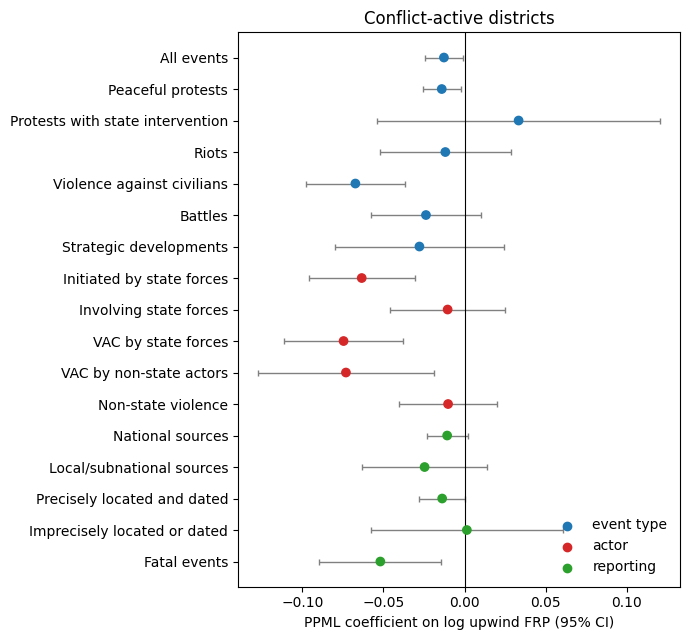

In [8]:
res = pd.DataFrame(rows)
res.to_csv(OUT_CSV, index=False)
print(f'Saved {len(res)} rows to {OUT_CSV}')

LABELS = {'all_events': 'All events', 'peaceful_protest': 'Peaceful protests', 'protest_intervention': 'Protests with state intervention',
          'riots': 'Riots', 'vac': 'Violence against civilians', 'battles': 'Battles', 'strategic_dev': 'Strategic developments',
          'state_initiated': 'Initiated by state forces', 'state_involved': 'Involving state forces',
          'vac_state': 'VAC by state forces', 'vac_nonstate': 'VAC by non-state actors', 'nonstate_violence': 'Non-state violence',
          'src_national': 'National sources', 'src_local': 'Local/subnational sources', 'precise': 'Precisely located and dated',
          'imprecise': 'Imprecisely located or dated', 'fatal_events': 'Fatal events'}
p = res[(res['sample'] == 'active') & res['group'].isin(GROUPS) & res['term'].eq('log_upwind_frp')].dropna(subset=['ppml_coef'])
p = p.iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 6.5))
colors = {'event type': '#1f77b4', 'actor': '#d62728', 'reporting': '#2ca02c'}
yy = np.arange(len(p))
ax.errorbar(p['ppml_coef'], yy, xerr=1.96 * p['ppml_se'], fmt='none', ecolor='grey', elinewidth=1, capsize=2)
ax.scatter(p['ppml_coef'], yy, c=p['group'].map(colors), zorder=3)
ax.axvline(0, color='k', lw=0.8)
ax.set_yticks(yy); ax.set_yticklabels(p['outcome'].map(LABELS))
ax.set_xlabel('PPML coefficient on log upwind FRP (95% CI)')
for g_, c in colors.items():
    ax.scatter([], [], c=c, label=g_)
ax.legend(loc='lower right', frameon=False)
ax.set_title('Conflict-active districts')
fig.tight_layout()
fig.savefig(OUT_PNG, dpi=200); fig.savefig(FIG_PNG, dpi=200)
plt.show()